In [1]:
from google.colab import files

uploaded = files.upload()

Saving development_data.csv to development_data.csv


In [2]:
import pandas as pd

df = pd.read_csv("development_data.csv")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (375, 7)


,Country Name,Country Code,Year,GDP per capita (current US$),"Inflation, consumer prices (annual %)","Unemployment, total (% of total labor force) (modeled ILO estimate)","Population, total"
0,Brazil,BRA,2000,3766.548115,7.044141,10.889,174018282
1,Brazil,BRA,2001,3176.289357,6.840359,10.649,176301203
2,Brazil,BRA,2002,2855.940189,8.450164,10.641,178503484
3,Brazil,BRA,2003,3090.607010,14.714920,11.168,180622688
4,Brazil,BRA,2004,3663.823188,6.597185,10.072,182675143


In [3]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Countries:", df["Country Name"].nunique())
print("Year range:", df["Year"].min(), "to", df["Year"].max())

Missing values in each column:


,0
Country Name,0
Country Code,0
Year,0
GDP per capita (current US$),0
"Inflation, consumer prices (annual %)",0
"Unemployment, total (% of total labor force) (modeled ILO estimate)",0
"Population, total",0


Duplicate rows: 0
Countries: 15
Year range: 2000 to 2024


In [4]:
# Compare GDP per capita across countries in 2024

latest = df[df["Year"] == 2024]

gdp_ranking = latest[
    ["Country Name", "GDP per capita (current US$)"]
].sort_values(
    by="GDP per capita (current US$)",
    ascending=False
)

display(gdp_ranking.reset_index(drop=True))

,Country Name,GDP per capita (current US$)
0,Ireland,112894.953200
1,United States,86169.664160
2,Netherlands,67465.320810
3,Germany,56103.732320
4,United Kingdom,53341.313110
5,France,46103.084090
6,Italy,40429.622400
7,Spain,35326.768310
8,Japan,33797.101430
9,Russian Federation,14961.897460


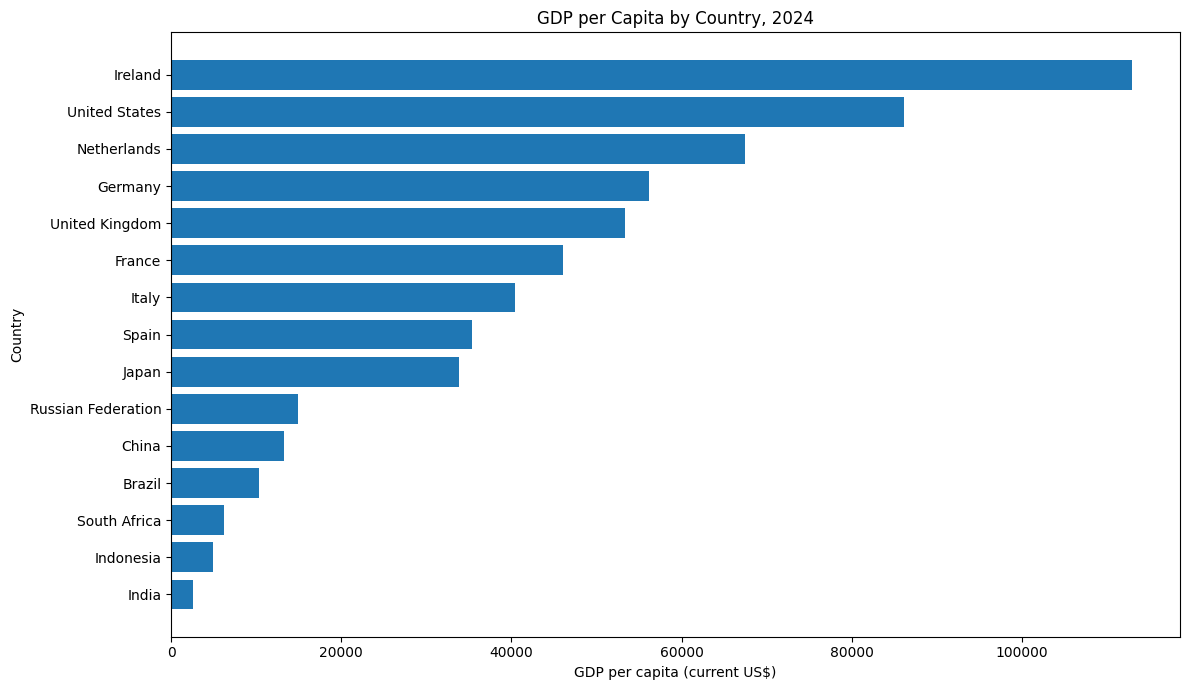

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    gdp_ranking["Country Name"],
    gdp_ranking["GDP per capita (current US$)"]
)

plt.xlabel("GDP per capita (current US$)")
plt.ylabel("Country")
plt.title("GDP per Capita by Country, 2024")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

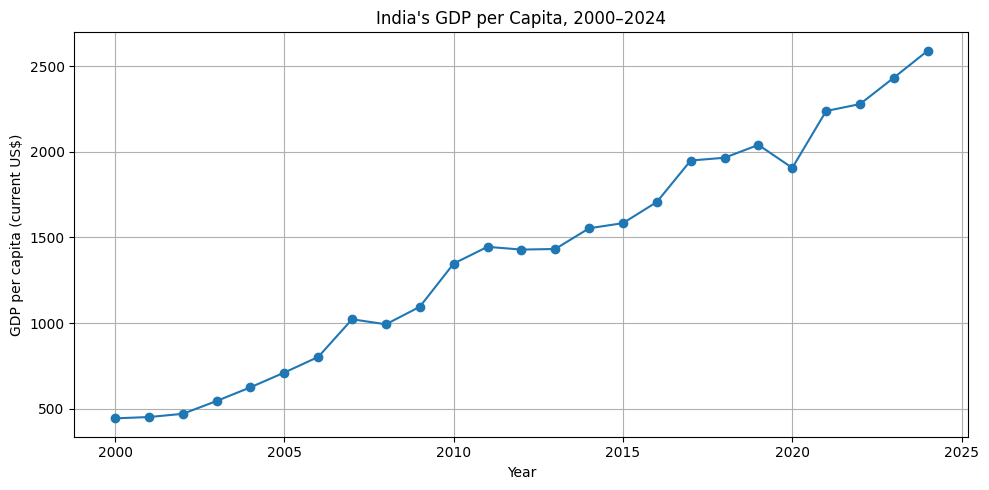

In [6]:
india = df[df["Country Name"] == "India"].sort_values("Year")

plt.figure(figsize=(10, 5))
plt.plot(
    india["Year"],
    india["GDP per capita (current US$)"],
    marker="o"
)

plt.title("India's GDP per Capita, 2000–2024")
plt.xlabel("Year")
plt.ylabel("GDP per capita (current US$)")
plt.grid(True)
plt.tight_layout()
plt.show()

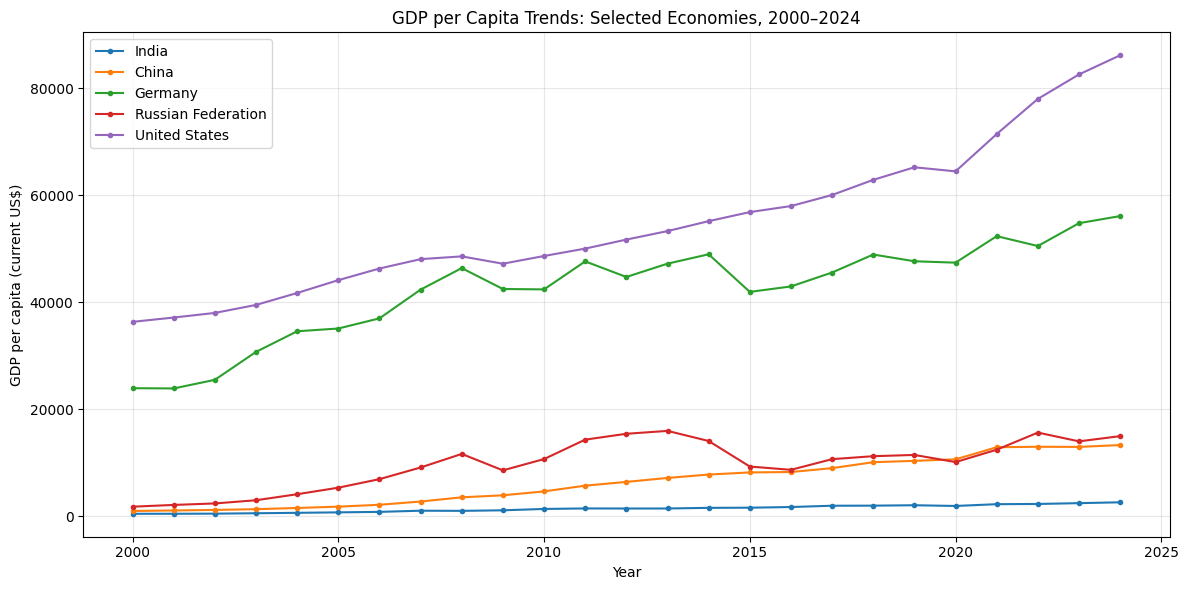

In [7]:
countries = [
    "India",
    "China",
    "Germany",
    "Russian Federation",
    "United States"
]

plt.figure(figsize=(12, 6))

for country in countries:
    country_data = df[df["Country Name"] == country].sort_values("Year")
    plt.plot(
        country_data["Year"],
        country_data["GDP per capita (current US$)"],
        marker="o",
        markersize=3,
        label=country
    )

plt.title("GDP per Capita Trends: Selected Economies, 2000–2024")
plt.xlabel("Year")
plt.ylabel("GDP per capita (current US$)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
latest = df[df["Year"] == 2024]

inflation_ranking = latest[
    ["Country Name", "Inflation, consumer prices (annual %)"]
].sort_values(
    by="Inflation, consumer prices (annual %)",
    ascending=False
)

display(inflation_ranking.reset_index(drop=True))

,Country Name,"Inflation, consumer prices (annual %)"
0,Russian Federation,8.434864
1,India,4.953036
2,Brazil,4.367464
3,South Africa,4.361152
4,Netherlands,3.346399
5,United Kingdom,3.271573
6,United States,2.949525
7,Spain,2.774070
8,Japan,2.738537
9,Germany,2.256498


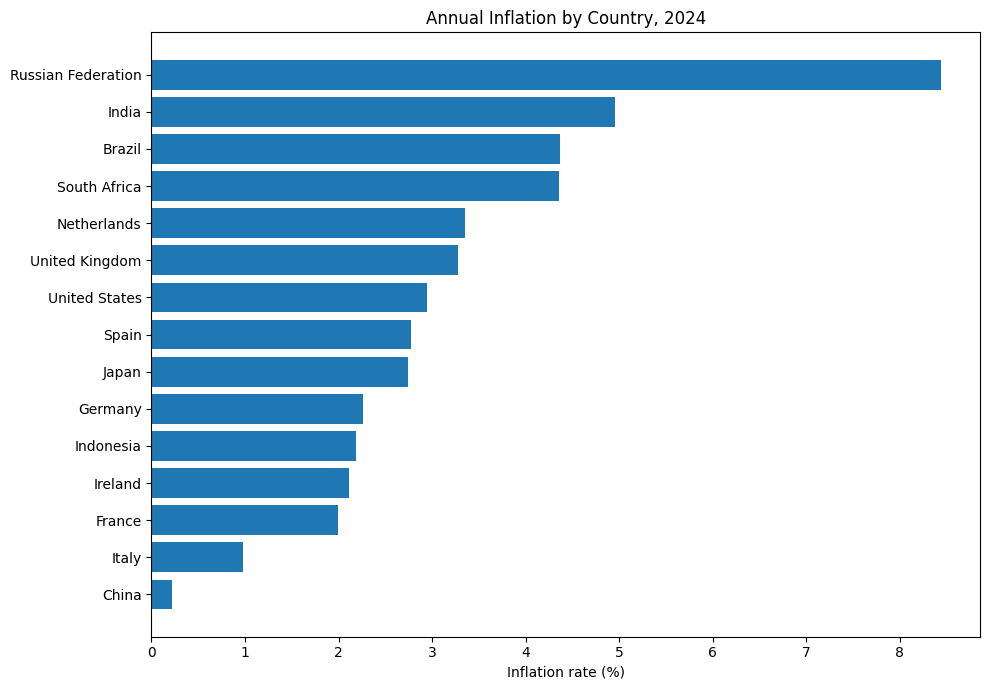

In [9]:
plt.figure(figsize=(10, 7))

plt.barh(
    inflation_ranking["Country Name"],
    inflation_ranking["Inflation, consumer prices (annual %)"]
)

plt.xlabel("Inflation rate (%)")
plt.title("Annual Inflation by Country, 2024")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [10]:
unemployment_ranking = latest[
    ["Country Name",
     "Unemployment, total (% of total labor force) (modeled ILO estimate)"]
].sort_values(
    by="Unemployment, total (% of total labor force) (modeled ILO estimate)",
    ascending=False
)

display(unemployment_ranking.reset_index(drop=True))

,Country Name,"Unemployment, total (% of total labor force) (modeled ILO estimate)"
0,South Africa,32.279
1,Spain,11.400
2,France,7.400
3,Brazil,6.801
4,Italy,6.500
5,China,4.590
6,United Kingdom,4.361
7,Ireland,4.300
8,India,4.173
9,United States,4.022


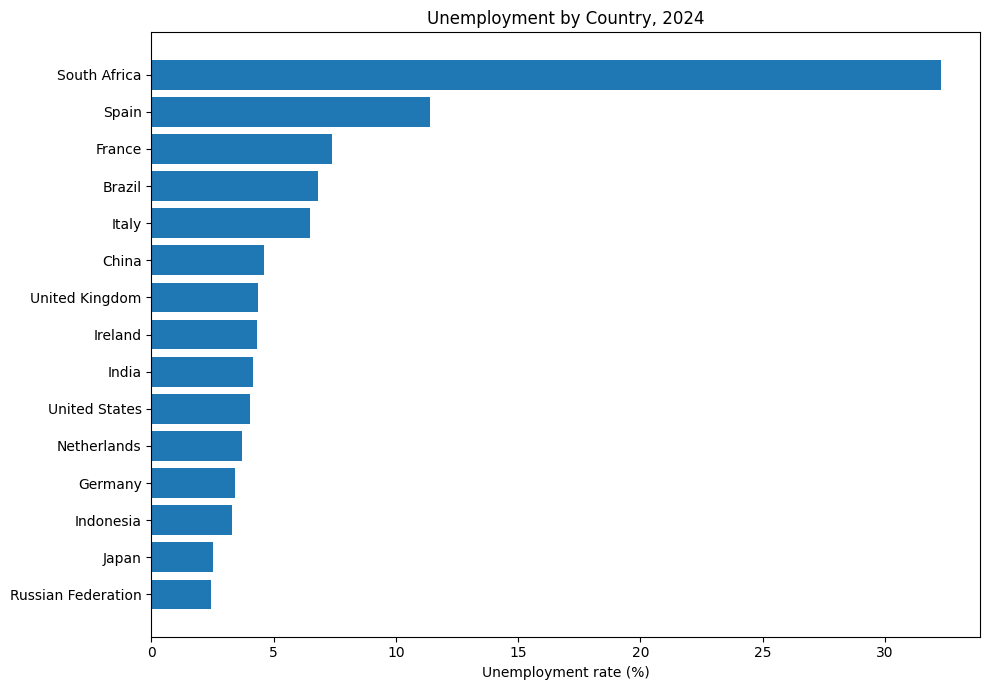

In [11]:
unemployment_col = (
    "Unemployment, total (% of total labor force) "
    "(modeled ILO estimate)"
)

plt.figure(figsize=(10, 7))

plt.barh(
    unemployment_ranking["Country Name"],
    unemployment_ranking[unemployment_col]
)

plt.xlabel("Unemployment rate (%)")
plt.title("Unemployment by Country, 2024")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [12]:
population_ranking = latest[
    ["Country Name", "Population, total"]
].sort_values(
    by="Population, total",
    ascending=False
)

display(population_ranking.reset_index(drop=True))

,Country Name,"Population, total"
0,India,1450935791
1,China,1408975000
2,United States,340003797
3,Indonesia,283487931
4,Brazil,211998573
5,Russian Federation,143669648
6,Japan,123975371
7,Germany,83516593
8,United Kingdom,69281000
9,France,68551653


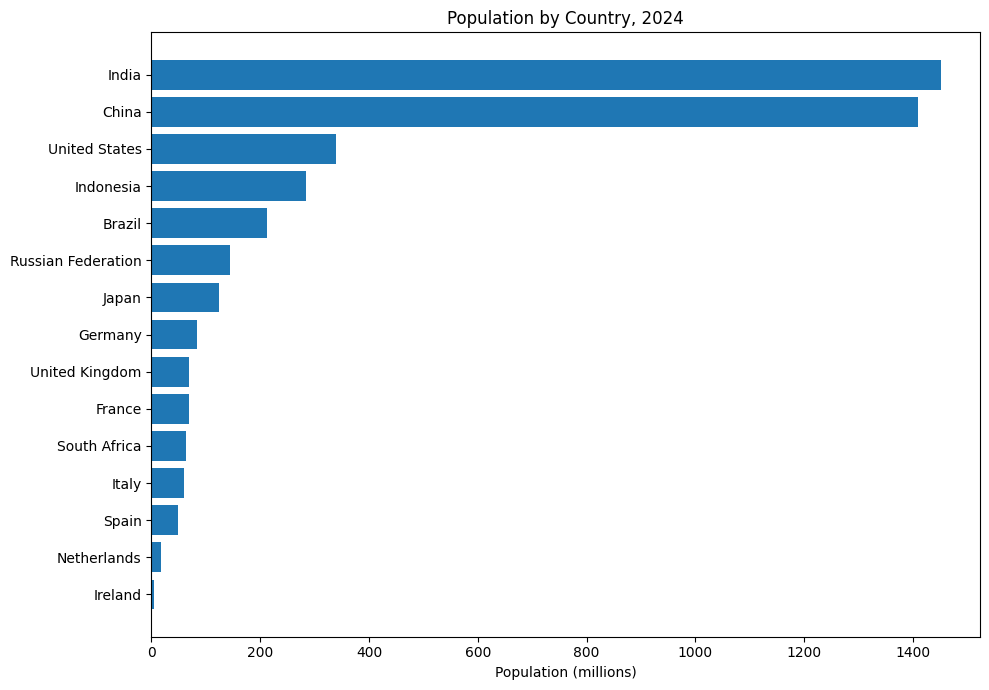

In [13]:
plt.figure(figsize=(10, 7))

plt.barh(
    population_ranking["Country Name"],
    population_ranking["Population, total"] / 1_000_000
)

plt.xlabel("Population (millions)")
plt.title("Population by Country, 2024")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [14]:
indicators = [
    "GDP per capita (current US$)",
    "Inflation, consumer prices (annual %)",
    "Unemployment, total (% of total labor force) (modeled ILO estimate)",
    "Population, total"
]

summary = df[indicators].describe().T
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max
GDP per capita (current US$),375.0,2.838037e+04,2.206625e+04,442.75,6723.55,30658.74,4.304849e+04,1.128949e+05
"Inflation, consumer prices (annual %)",375.0,3.560000e+00,3.380000e+00,-4.45,1.44,2.67,4.950000e+00,2.148000e+01
"Unemployment, total (% of total labor force) (modeled ILO estimate)",375.0,8.350000e+00,5.950000e+00,2.12,4.55,6.78,9.270000e+00,3.401000e+01
"Population, total",375.0,2.696731e+08,4.190821e+08,3805174.00,57174687.50,82376451.00,2.324117e+08,1.450936e+09


In [15]:
gdp_growth = df[df["Year"].isin([2000, 2024])].pivot(
    index="Country Name",
    columns="Year",
    values="GDP per capita (current US$)"
)

gdp_growth["Change (%)"] = (
    (gdp_growth[2024] - gdp_growth[2000])
    / gdp_growth[2000] * 100
)

display(gdp_growth.round(2).sort_values("Change (%)", ascending=False))

Year,2000,2024,Change (%)
Country Name,,,
China,969.20,13293.12,1271.56
Russian Federation,1771.59,14961.90,744.54
Indonesia,763.71,4925.44,544.93
India,442.75,2591.99,485.43
Ireland,26334.57,112894.95,328.69
Brazil,3766.55,10310.55,173.74
Netherlands,26225.17,67465.32,157.25
Spain,14743.27,35326.77,139.61
United States,36329.97,86169.66,137.19


In [16]:
with pd.ExcelWriter("Python_Analysis_Results.xlsx") as writer:
    gdp_ranking.to_excel(writer, sheet_name="GDP_2024", index=False)
    inflation_ranking.to_excel(writer, sheet_name="Inflation_2024", index=False)
    unemployment_ranking.to_excel(writer, sheet_name="Unemployment_2024", index=False)
    population_ranking.to_excel(writer, sheet_name="Population_2024", index=False)
    summary.to_excel(writer, sheet_name="Summary_Statistics")
    gdp_growth.to_excel(writer, sheet_name="GDP_Growth_2000_2024")

print("Analysis results exported successfully.")

Analysis results exported successfully.


In [17]:
from google.colab import files
files.download("Python_Analysis_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>